<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/VQC_PhishingURL_Shahriyar2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC for phishing-URL detection: PhishVQC (Shahriyar et al., 2025) step by step

This notebook re-implements, runs and checks the method of

> Md. Farhan Shahriyar, Gazi Tanbhir, Abdullah Md Raihan Chy, Mohammed Abdul Al Arafat Tanzin and Md. Jisan Mashrafi,
> "PhishVQC: Optimizing Phishing URL Detection with Correlation Based Feature Selection and Variational Quantum Classifier",
> arXiv:2503.01799 [cs.CR], 3 March 2025. https://arxiv.org/abs/2503.01799

The paper publishes no code, so everything below is written from the method as the six-page paper describes it, with the
same software stack it names (Qiskit, qiskit-machine-learning, scikit-learn, pandas).

**What the notebook does.** It downloads the PhiUSIIL phishing-URL dataset from the UCI repository, reproduces the paper's
preprocessing (null check, correlation-based feature selection with threshold 0.5, normalisation), encodes each URL's
feature vector into the amplitudes of a 5-qubit state with `raw_feature_vector`, trains a Variational Quantum Classifier
(VQC) with the `RealAmplitudes` and `EfficientSU2` ansaetze (entanglement `full`, COBYLA, 300 iterations, statevector
sampler), and reports phishing precision, phishing recall and macro F1 exactly as the paper's Table III does. Three
classical models are trained on the identical 32-dimensional inputs, and the last section puts the paper's numbers next to
ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs
pinned Qiskit versions; if Colab asks to restart the session, restart and run all again. Nothing in the notebook needs a GPU or
an IBM Quantum account.

**Runtime.** With `FAST_MODE = True` (160 training URLs, 40 test URLs, 40 COBYLA iterations, 2 ansatz repetitions) the whole
notebook runs in about 5 minutes on a Colab CPU. With `FAST_MODE = False` the paper's *ASetup* (640 / 160 URLs, 300
iterations, 3 repetitions) took 67 minutes on the validation machine (a shared laptop CPU): 19 minutes for
`RealAmplitudes`, whose COBYLA run converged after 169 evaluations, and 47 minutes for `EfficientSU2`, which used all 300.
Switching `RUN_BSETUP = True` adds the paper's *BSetup* (960 / 240 URLs, 4 repetitions) and roughly another two hours.
The committed notebook contains the outputs of the full ASetup run.

**What you get at the end.** The paper's Table III (precision, recall, macro F1 for both ansaetze) re-computed, its loss-curve
callback and wall-time figure re-drawn, confusion matrices with phishing as the positive class, three classical baselines on the
same inputs, a side-by-side comparison with the paper's values, a critical reading of the paper, and five exercises.

## The paper in one page

**Problem.** Decide from a URL and the page behind it whether it is a phishing site (class 0) or legitimate (class 1).

**Decision.** Binary classification of a pre-computed feature vector; the output of the VQC is the class with the larger
measured probability under a parity read-out of the 5-qubit register.

**Method (PhishVQC).** Classical preprocessing -> amplitude encoding with Qiskit's `RawFeatureVector` (32 numbers -> 5
qubits, Eq. 1-2 of the paper) -> a variational ansatz (`RealAmplitudes` or `EfficientSU2`, `entanglement="full"`, 3 or 4
repetitions) -> measurement -> COBYLA (300 iterations) updates the ansatz parameters to minimise the cross-entropy loss ->
a callback plots the loss at every iteration. Everything is simulated with Qiskit's `StatevectorSampler`.

**Data.** PhiUSIIL Phishing URL Dataset (Prasad and Chandra, 2024; UCI repository id 967): 134,850 legitimate and 100,945
phishing URLs, 54 features (URL structure, obfuscation, HTML content, page behaviour).

**Preprocessing.** Null check; correlation analysis with threshold 0.5 that reduces 54 to 32 features; normalisation.

**Experiments.** *ASetup*: 640 training / 160 test URLs, 3 repetitions. *BSetup*: 960 / 240 URLs, 4 repetitions.

**Claims (Table III and Fig. 5).**

| Setup | Ansatz | Phishing precision | Phishing recall | Macro F1 | Wall time |
|---|---|---|---|---|---|
| ASetup | RealAmplitudes | 0.97 (printed as "0.097") | 0.81 | 0.89 | 1534 s |
| ASetup | EfficientSU2 | 0.93 | 0.87 | 0.89 | "about 40 % slower" (~2150 s) |
| BSetup | RealAmplitudes | 0.96 | 0.80 | 0.88 | "nearly half" of 6584 s (~3300 s) |
| BSetup | EfficientSU2 | 0.90 | 0.84 | 0.87 | 6584 s |

The abstract also claims a "22 % improvement over prior studies" (macro F1 0.89 vs 0.67 of Ray et al. [10]).

## What follows the paper and what had to be chosen

The paper fixes the dataset, the feature-selection threshold, the encoding, the ansaetze, the optimiser, the iteration budget
and the sample sizes. It does not say how the 640 / 160 URLs were drawn, which correlation coefficient and tie-breaking rule
were used, which normaliser was applied, or which random seed fixed the split. Where the paper is silent this notebook makes a
choice and says so in the code (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | PhiUSIIL, UCI id 967 | Same, downloaded inside the notebook (`ucimlrepo`, fallback: UCI zip) |
| Null check | "missing or null values are checked" | Same (the file has none) |
| Non-numeric columns | not mentioned (54 features include URL, Domain, TLD, Title strings) | Dropped (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`): 50 numeric features remain |
| Correlation filter | "threshold 0.5", 54 -> 32 features | Pearson \|r\| > 0.5 between features, drop the later column of each pair, **fitted on the training pool only**; this yields 29 features (paper: 32); the gap is documented, not forced |
| Normalisation | "normalization is applied" | Min-max to [0, 1] fitted on the training pool, test values clipped; then zero-padding to 32 and L2 normalisation per sample, which `raw_feature_vector` requires |
| Sampling of 640 / 160 (960 / 240) | not described | Class-balanced random samples with `random_state = SEED` from disjoint training / test pools |
| Train / test split seed | not given | `SEED = 42` |
| Sampler | `StatevectorSampler` | Same, `default_shots = 1024`, seeded |
| Loss, read-out | not stated (VQC defaults) | VQC defaults: cross-entropy loss, parity interpretation |
| Classical baseline | none in the paper | Logistic regression, RBF-SVM, random forest on identical inputs (added) |
| BSetup | run | Optional (`RUN_BSETUP`), off by default because it adds about two hours on CPU |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc ucimlrepo
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE  = False         # True: class demo in about 5 minutes. False: the paper's ASetup (about 70 min on a 2-core CPU).
RUN_BSETUP = False          # True: also run the paper's BSetup (960 / 240 URLs, 4 repetitions; adds about 2 h on CPU).

SEED       = 42             # CHOICE: the paper gives no seed
N_FEATURES_PADDED = 32      # amplitude encoding needs a power of two; the paper pads to 32 -> 5 qubits
N_QUBITS   = 5

# Experimental setups of the paper (Table I / II): name -> (n_train, n_test, ansatz repetitions)
if FAST_MODE:
    SETUPS  = {"FAST": (160, 40, 2)}
    MAXITER = 40
else:
    SETUPS  = {"ASetup": (640, 160, 3)}
    if RUN_BSETUP:
        SETUPS["BSetup"] = (960, 240, 4)
    MAXITER = 300           # paper: COBYLA, maximum 300 iterations

ANSATZE    = ["RealAmplitudes", "EfficientSU2"]
ENTANGLE   = "full"         # paper: entanglement='full'
CORR_THRESHOLD = 0.5        # paper: correlation threshold 0.5
SHOTS      = 1024           # CHOICE: StatevectorSampler default shot count
TEST_POOL_FRACTION = 0.2    # CHOICE: share of the full dataset held out as the test pool
N_BASELINE_REPEATS = 5      # repeated draws for the classical baselines (mean +- std)

DATA_DIR   = "data"         # where the CSV is cached (relative to the working directory)
UCI_ID     = 967            # PhiUSIIL Phishing URL Dataset in the UCI repository
UCI_ZIP    = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"

In [3]:
import os, io, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, normalize
from sklearn.metrics import (classification_report, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)

import qiskit, qiskit_machine_learning
from qiskit import transpile
from qiskit.circuit.library import real_amplitudes, efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| setups:", SETUPS, "| MAXITER =", MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | pandas 3.0.6
scikit-learn 1.9.1
FAST_MODE = False | setups: {'ASetup': (640, 160, 3)} | MAXITER = 300


## 1. The PhiUSIIL phishing-URL dataset

PhiUSIIL (Prasad and Chandra, *Computers & Security* 136, 2024) lists 235,795 URLs. For every URL the authors computed
features of three kinds: the URL string itself (length, digits, obfuscated characters, similarity to known domains), the
page's HTML (lines of code, number of images, scripts, iframes, forms, hidden fields, password fields) and page behaviour
(redirects, pop-ups, social-network links, copyright notice, keywords such as *bank*, *pay*, *crypto*). The label is 1 for a
legitimate URL and 0 for phishing. The paper uses the file as published on the UCI Machine Learning Repository (id 967).

The cell below fetches it with the `ucimlrepo` client; if that fails (no package, or an API change) it downloads the UCI zip
directly. The CSV is cached in `DATA_DIR`, so a second run does not download again. The paper's first preprocessing step,
the check for missing values, is done right away.

In [4]:
CSV_PATH = os.path.join(DATA_DIR, "PhiUSIIL_Phishing_URL_Dataset.csv")

def fetch_phiusiil(path):
    if os.path.exists(path):
        print("using cached", path)
        return pd.read_csv(path)
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=UCI_ID)
        df = pd.concat([ds.data.ids, ds.data.features, ds.data.targets], axis=1) if ds.data.ids is not None \
             else pd.concat([ds.data.features, ds.data.targets], axis=1)
        print("downloaded with ucimlrepo (id=%d)" % UCI_ID)
    except Exception as e:                      # fallback: the raw zip from UCI
        import requests
        print("ucimlrepo unavailable (%s); downloading the UCI zip" % type(e).__name__)
        r = requests.get(UCI_ZIP, timeout=180); r.raise_for_status()
        z = zipfile.ZipFile(io.BytesIO(r.content))
        name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        df = pd.read_csv(z.open(name))
    df.to_csv(path, index=False)
    return df

t0 = time.time()
df = fetch_phiusiil(CSV_PATH)
print(f"loaded in {time.time()-t0:.1f} s: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("missing values:", int(df.isnull().sum().sum()), "   (paper: null check)")
print("class counts  :", df["label"].value_counts().rename({1: "legitimate (1)", 0: "phishing (0)"}).to_dict(),
      "   (paper: 134,850 legitimate, 100,945 phishing)")
df.head(3)

using cached data\PhiUSIIL_Phishing_URL_Dataset.csv


loaded in 3.1 s: 235,795 rows x 56 columns
missing values: 0    (paper: null check)
class counts  : {'legitimate (1)': 134850, 'phishing (0)': 100945}    (paper: 134,850 legitimate, 100,945 phishing)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1


## 2. Training pool, test pool and the paper's sample sizes

The paper trains on 640 URLs and tests on 160 (ASetup), or 960 / 240 (BSetup), but does not say how those rows were drawn
from the 235,795. We draw **class-balanced random samples**: half phishing, half legitimate, so that precision and recall are
not inflated by the 57 : 43 class ratio of the full file.

To keep the "fit everything on training data only" rule, the full dataset is first split, stratified by label, into a
**training pool** (80 %) and a **test pool** (20 %). Every fitted preprocessing step (the correlation filter and the min-max
scaler) sees only the training pool, and every test URL comes from the test pool. The quantum model itself only ever sees
the 640 (or 960) sampled training URLs.

Five text columns (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`) cannot be correlated or amplitude-encoded and are dropped;
the paper's "54 features" count includes them, so 50 numeric features enter the feature selection.

In [5]:
TEXT_COLS = [c for c in ["FILENAME", "URL", "Domain", "TLD", "Title"] if c in df.columns]
feature_cols = [c for c in df.columns if c not in TEXT_COLS + ["label"]]
X_num = df[feature_cols].apply(pd.to_numeric, errors="coerce")
assert X_num.isnull().sum().sum() == 0, "non-numeric values found"
print(f"dropped text columns: {TEXT_COLS}")
print(f"numeric features entering feature selection: {len(feature_cols)}   (paper counts 54 incl. the text columns)")

pool_train, pool_test = train_test_split(df.index.values, test_size=TEST_POOL_FRACTION,
                                         stratify=df["label"], random_state=SEED)
print(f"training pool: {len(pool_train):,} URLs | test pool: {len(pool_test):,} URLs (disjoint, stratified)")

def balanced_sample(pool_idx, n, seed):
    """# CHOICE: n/2 phishing + n/2 legitimate URLs drawn at random from a pool of row indices."""
    lab = df.loc[pool_idx, "label"]
    r = np.random.default_rng(seed)
    pick = np.concatenate([r.choice(lab.index[lab == 0].values, n // 2, replace=False),
                           r.choice(lab.index[lab == 1].values, n - n // 2, replace=False)])
    return r.permutation(pick)

samples = {}
for name, (n_tr, n_te, reps) in SETUPS.items():
    samples[name] = (balanced_sample(pool_train, n_tr, SEED), balanced_sample(pool_test, n_te, SEED + 1))
    print(f"{name}: {n_tr} training URLs, {n_te} test URLs, ansatz reps = {reps}")

dropped text columns: ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']
numeric features entering feature selection: 50   (paper counts 54 incl. the text columns)


training pool: 188,636 URLs | test pool: 47,159 URLs (disjoint, stratified)
ASetup: 640 training URLs, 160 test URLs, ansatz reps = 3


## 3. Correlation-based feature selection (threshold 0.5)

The paper cites Hall's correlation-based feature selection and says: a good feature set is "strongly correlated with the
target class but uncorrelated with each other", a threshold of 0.5 is set, and the feature count falls from 54 to 32. The
most common reading of such a sentence is the usual *pairwise redundancy filter*: compute the absolute Pearson correlation
between every pair of features and, whenever a pair exceeds 0.5, drop one of the two. We keep the first column of each pair
(in the file's column order) and drop the later one.

On the training pool this leaves **29 features**, not the paper's 32. The paper does not give its column list, so the
difference may come from a different coefficient (Spearman), a different tie-breaking rule, counting the text columns, or
computing the correlation on a small sample (on 800 rows the same rule keeps only about 24 features). We keep what the rule
gives and record the number as a deviation; after zero-padding both end up as 32 amplitudes on 5 qubits, exactly as in the
paper.

features before: 50 | dropped (|r| > 0.5): 21 | kept: 29   (paper: 54 -> 32)
dropped: ['CharContinuationRate', 'URLCharProb', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'NoOfSelfRedirect', 'HasDescription', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasCopyrightInfo', 'NoOfExternalRef']
kept   : ['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'TLDLegitimateProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfQMarkInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef']


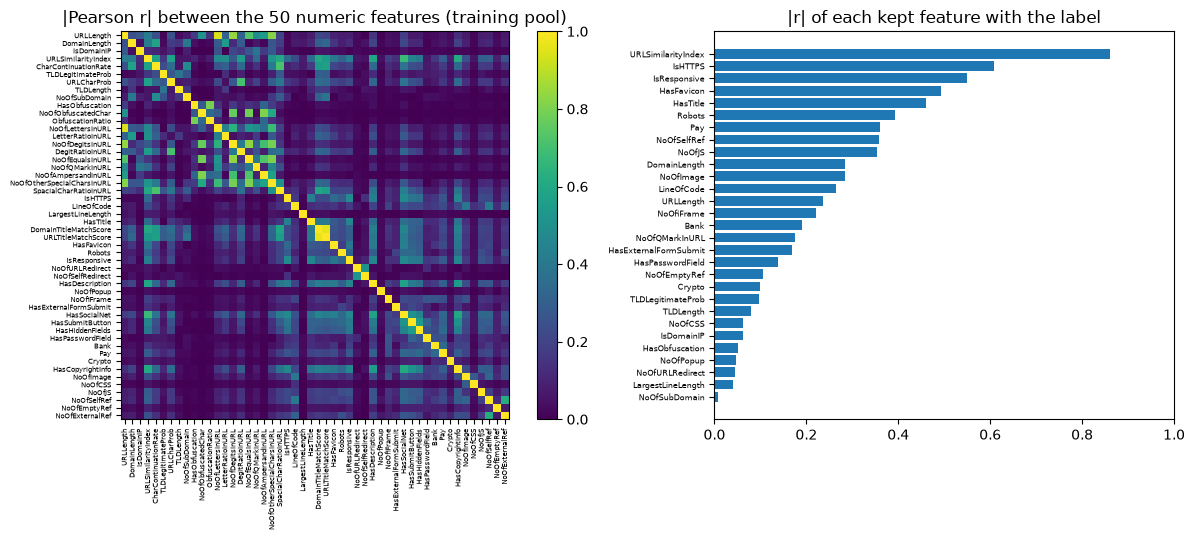

In [6]:
corr = X_num.loc[pool_train].corr().abs()                     # Pearson |r| on the training pool only
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
dropped = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]   # CHOICE: drop the later column of each pair
selected = [c for c in feature_cols if c not in dropped]
print(f"features before: {len(feature_cols)} | dropped (|r| > {CORR_THRESHOLD}): {len(dropped)} | kept: {len(selected)}   (paper: 54 -> 32)")
print("dropped:", dropped)
print("kept   :", selected)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.25, 1]})
im = axes[0].imshow(corr.values, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title(f"|Pearson r| between the {len(feature_cols)} numeric features (training pool)")
axes[0].set_xticks(range(len(feature_cols))); axes[0].set_xticklabels(feature_cols, rotation=90, fontsize=5)
axes[0].set_yticks(range(len(feature_cols))); axes[0].set_yticklabels(feature_cols, fontsize=5)
fig.colorbar(im, ax=axes[0], fraction=0.046)
target_corr = X_num.loc[pool_train, selected].corrwith(df.loc[pool_train, "label"]).abs().sort_values()
axes[1].barh(target_corr.index, target_corr.values, color="tab:blue")
axes[1].set_title("|r| of each kept feature with the label"); axes[1].tick_params(axis="y", labelsize=6)
axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

## 4. Normalisation and amplitude encoding (`raw_feature_vector`)

Amplitude encoding writes the feature vector $x \in \mathbb{R}^{2^n}$ directly into the amplitudes of an $n$-qubit state,
$|\psi(x)\rangle = \sum_i c_i |i\rangle$ with $c_i = x_i / \|x\|$ (paper, Eq. 2). Two consequences follow:

* the vector length must be a power of two, so 29 features are **zero-padded to 32** and encoded on $n = \log_2 32 = 5$
  qubits (paper, Eq. 1);
* a quantum state has unit norm, so each sample is divided by its own L2 norm. Qiskit's `raw_feature_vector` does this
  normalisation itself, but we do it explicitly so that the classical baselines receive *exactly* the same vectors. Note
  what is lost: two URLs whose feature vectors differ only by a common factor become the same quantum state.

The paper only says "normalization is applied". We scale every kept feature to $[0, 1]$ with a min-max scaler fitted on the
training pool (test values are clipped to the training range) before the L2 step; without that first step the few
large-valued counts (`LineOfCode`, `URLLength`, ...) would dominate every amplitude.

ASetup: X_train (640, 32), X_test (160, 32), norms all 1: True, train classes [320 320], test classes [80 80]

raw_feature_vector(32): 5 qubits, 32 input parameters


state preparation for one concrete URL, compiled to u/cx gates: depth 54, gate counts {'u': 31, 'cx': 26, 'reset': 5}
(this is why amplitude encoding is cheap in qubits but expensive in gates, and why Aer cannot run it with unbound parameters)


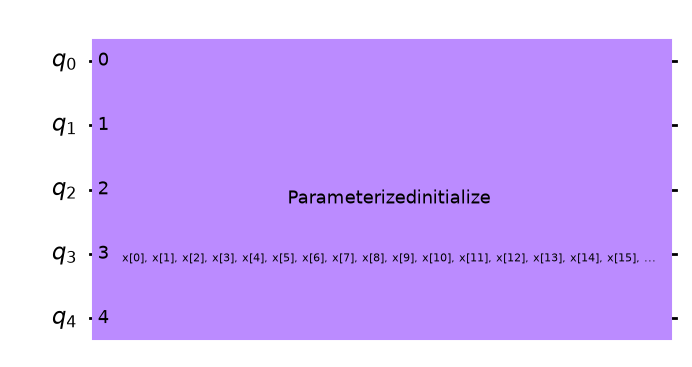

In [7]:
scaler = MinMaxScaler().fit(X_num.loc[pool_train, selected])        # fitted on the training pool only

def encode(idx):
    """Rows -> min-max scaled, clipped, zero-padded to 32, L2-normalised vectors (what raw_feature_vector expects)."""
    x = np.clip(scaler.transform(X_num.loc[idx, selected]), 0.0, 1.0)
    x = np.hstack([x, np.zeros((len(x), N_FEATURES_PADDED - x.shape[1]))])
    return normalize(x, norm="l2")

data = {}
for name, (tr_idx, te_idx) in samples.items():
    data[name] = dict(X_train=encode(tr_idx), y_train=df.loc[tr_idx, "label"].values,
                      X_test=encode(te_idx),  y_test=df.loc[te_idx, "label"].values)
    d = data[name]
    print(f"{name}: X_train {d['X_train'].shape}, X_test {d['X_test'].shape}, "
          f"norms all 1: {np.allclose(np.linalg.norm(d['X_train'], axis=1), 1.0)}, "
          f"train classes {np.bincount(d['y_train'])}, test classes {np.bincount(d['y_test'])}")

feature_map = raw_feature_vector(N_FEATURES_PADDED)
print(f"\nraw_feature_vector({N_FEATURES_PADDED}): {feature_map.num_qubits} qubits, {feature_map.num_parameters} input parameters")
first = list(data.values())[0]["X_train"][0]
bound = transpile(feature_map.assign_parameters(first), basis_gates=["u", "cx"], optimization_level=1)
print(f"state preparation for one concrete URL, compiled to u/cx gates: depth {bound.depth()}, gate counts {dict(bound.count_ops())}")
print("(this is why amplitude encoding is cheap in qubits but expensive in gates, and why Aer cannot run it with unbound parameters)")
feature_map.draw("mpl", fold=-1, style="clifford")

## 5. Classical baselines on identical inputs

The paper compares PhishVQC only with another quantum model on a different dataset. Before training anything quantum we
therefore ask the obvious question: what does a plain classical classifier achieve on *exactly* the 32-dimensional unit
vectors the VQC will see, and on the same 640 / 160 URLs? Three models are used: logistic regression (a linear decision
boundary, like one layer of a network), an RBF support-vector machine and a random forest.

Because a test set of 160 URLs makes every metric noisy, the baselines are repeated over `N_BASELINE_REPEATS` independent
balanced draws (same pools, different seeds), and the first draw is the one shared with the VQC.

In [8]:
def baselines():
    return {"LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
            "SVC (rbf)":          SVC(kernel="rbf", C=1.0, random_state=SEED),
            "RandomForest":       RandomForestClassifier(n_estimators=200, random_state=SEED)}

def phishing_metrics(y_true, y_pred):
    """Paper's Table III columns: precision and recall of the phishing class (label 0) and macro-averaged F1."""
    return dict(phish_precision=precision_score(y_true, y_pred, pos_label=0),
                phish_recall=recall_score(y_true, y_pred, pos_label=0),
                macro_f1=f1_score(y_true, y_pred, average="macro"))

baseline_rows = []
for setup, (n_tr, n_te, reps) in SETUPS.items():
    for rep in range(N_BASELINE_REPEATS):
        if rep == 0:
            d = data[setup]                                   # the exact draw the VQC uses
        else:
            tr_idx = balanced_sample(pool_train, n_tr, SEED + 100 + rep)
            te_idx = balanced_sample(pool_test, n_te, SEED + 200 + rep)
            d = dict(X_train=encode(tr_idx), y_train=df.loc[tr_idx, "label"].values,
                     X_test=encode(te_idx),  y_test=df.loc[te_idx, "label"].values)
        for mname, model in baselines().items():
            t0 = time.perf_counter()
            model.fit(d["X_train"], d["y_train"]); pred = model.predict(d["X_test"])
            baseline_rows.append(dict(setup=setup, model=mname, draw=rep, seconds=time.perf_counter() - t0,
                                      **phishing_metrics(d["y_test"], pred)))
baseline_df = pd.DataFrame(baseline_rows)
baseline_first = baseline_df[baseline_df.draw == 0].set_index(["setup", "model"])
baseline_summary = (baseline_df.groupby(["setup", "model"])[["phish_precision", "phish_recall", "macro_f1"]]
                    .agg(["mean", "std"]).round(3))
print("Classical baselines on the VQC's own draw (draw 0):")
display(baseline_first[["phish_precision", "phish_recall", "macro_f1", "seconds"]].round(3))
print(f"\nMean +- std over {N_BASELINE_REPEATS} balanced draws:")
display(baseline_summary)

# What does the per-sample L2 normalisation (forced by amplitude encoding) cost? Same models, same draw,
# same 29 features, min-max scaling only (no zero-padding, no unit norm).
noL2_rows = []
for setup, (tr_idx, te_idx) in samples.items():
    Xtr = np.clip(scaler.transform(X_num.loc[tr_idx, selected]), 0, 1)
    Xte = np.clip(scaler.transform(X_num.loc[te_idx, selected]), 0, 1)
    for mname, model in baselines().items():
        model.fit(Xtr, df.loc[tr_idx, "label"].values)
        noL2_rows.append(dict(setup=setup, model=mname, **phishing_metrics(df.loc[te_idx, "label"].values, model.predict(Xte))))
baseline_noL2 = pd.DataFrame(noL2_rows).set_index(["setup", "model"]).round(3)
print("\nSame models and draw 0, min-max scaled features WITHOUT the per-sample L2 normalisation:")
display(baseline_noL2)

Classical baselines on the VQC's own draw (draw 0):


phish_precision  phish_recall  macro_f1  seconds
setup  model                                                               
ASetup LogisticRegression            0.947         0.900     0.925    0.022
       SVC (rbf)                     1.000         0.962     0.981    0.018
       RandomForest                  0.988         1.000     0.994    0.694


Mean +- std over 5 balanced draws:


phish_precision        phish_recall        macro_f1       
                                     mean    std         mean    std     mean    std
setup  model                                                                        
ASetup LogisticRegression           0.971  0.023        0.882  0.030    0.927  0.011
       RandomForest                 0.990  0.010        0.995  0.011    0.992  0.005
       SVC (rbf)                    1.000  0.000        0.978  0.016    0.989  0.008


Same models and draw 0, min-max scaled features WITHOUT the per-sample L2 normalisation:


phish_precision  phish_recall  macro_f1
setup  model                                                      
ASetup LogisticRegression              1.0         0.962     0.981
       SVC (rbf)                       1.0         0.988     0.994
       RandomForest                    1.0         1.000     1.000

## 6. The two ansaetze: `RealAmplitudes` and `EfficientSU2`

Both circuits alternate a layer of single-qubit rotations with a layer of entangling CNOTs, repeated `reps` times, with a
final rotation layer. `RealAmplitudes` uses only $R_Y$ rotations, so the prepared state has real amplitudes (hence the
name): $5 \times (\text{reps}+1)$ parameters, i.e. 20 for the paper's 3 repetitions. `EfficientSU2` uses an $R_Y$ *and* an
$R_Z$ rotation per qubit and layer, twice as many parameters (40 for 3 repetitions). With `entanglement="full"` every layer
contains a CNOT between every pair of qubits (10 CNOTs per layer on 5 qubits), which is what the paper's Fig. 3 and 4 show.

In the VQC the data circuit (`raw_feature_vector`) is followed by the ansatz, all five qubits are measured, and the parity of
the measured bit-string decides the class (the default `interpret` of Qiskit's `VQC`).

RealAmplitudes(reps=3, entanglement='full'): 20 trainable parameters, depth 21


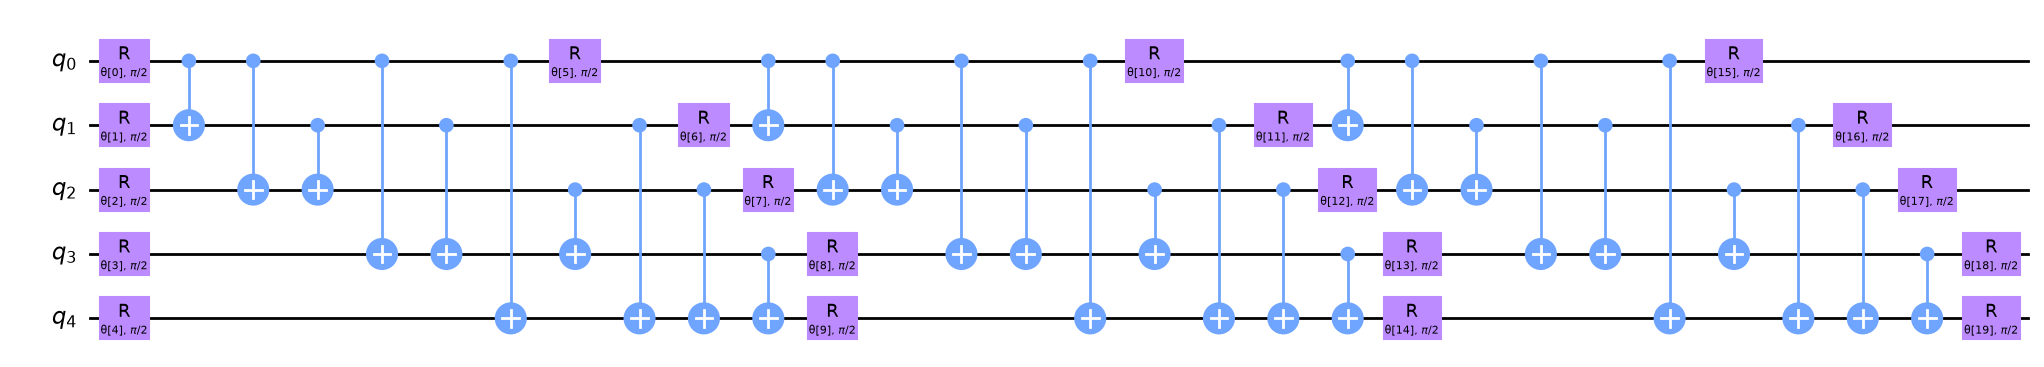

EfficientSU2(reps=3, entanglement='full'): 40 trainable parameters, depth 25


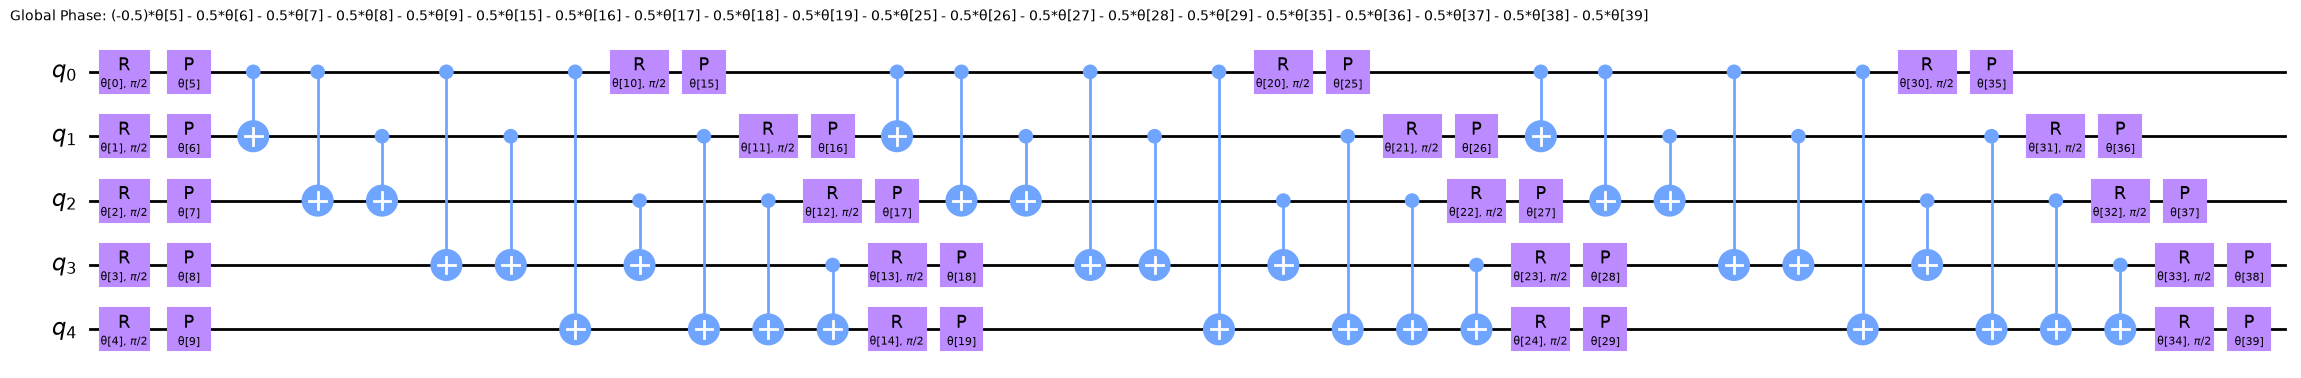

In [9]:
def make_ansatz(name, reps):
    if name == "RealAmplitudes":
        return real_amplitudes(N_QUBITS, reps=reps, entanglement=ENTANGLE)
    if name == "EfficientSU2":
        return efficient_su2(N_QUBITS, reps=reps, entanglement=ENTANGLE)
    raise ValueError(name)

reps_shown = list(SETUPS.values())[0][2]
for name in ANSATZE:
    ans = make_ansatz(name, reps_shown)
    print(f"{name}(reps={reps_shown}, entanglement='{ENTANGLE}'): {ans.num_parameters} trainable parameters, "
          f"depth {ans.decompose().depth()}")
    display(ans.decompose().draw("mpl", fold=-1, style="clifford"))

## 7. Training PhishVQC

For every setup and ansatz a `VQC` is built from the amplitude-encoding feature map, the ansatz, a COBYLA optimiser with the
paper's 300-iteration budget and a seeded `StatevectorSampler`. COBYLA is derivative-free: each iteration evaluates the loss
once, which means running all 640 training circuits through the simulator (7-10 s per evaluation on the laptop CPU used for
validation). COBYLA may also stop before the 300th evaluation when its trust region has shrunk below its tolerance, which
is what happened to `RealAmplitudes` in our run (169 evaluations). The callback stores the loss after every evaluation and redraws the loss curve every ten evaluations, which is
the paper's "callback that plots the objective function value at each iteration".

Two practical notes. `raw_feature_vector` contains a state-initialisation instruction that Qiskit Aer cannot run inside a
parameterised circuit, so the reference `StatevectorSampler` from `qiskit.primitives` is the right (and the paper's) choice.
And the VQC's prediction is read from 1024 shots per circuit, so the loss curve is slightly noisy even on an exact simulator.

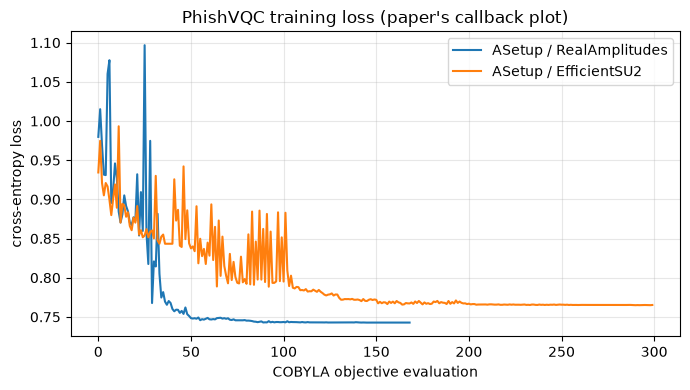

ASetup  RealAmplitudes reps=3 params= 20 evals= 169 fit  1141.3 s | train acc 0.784 | phish P 0.911 R 0.637 | macro F1 0.783
ASetup  EfficientSU2   reps=3 params= 40 evals= 300 fit  2839.8 s | train acc 0.817 | phish P 0.982 R 0.688 | macro F1 0.834


In [10]:
results = {}            # (setup, ansatz) -> dict with metrics, predictions, losses, timings
loss_curves = {}

def draw_losses(final=False):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    for key, losses in loss_curves.items():
        ax.plot(losses, label=f"{key[0]} / {key[1]}")
    ax.set_xlabel("COBYLA objective evaluation"); ax.set_ylabel("cross-entropy loss")
    ax.set_title("PhishVQC training loss (paper's callback plot)"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

for setup, (n_tr, n_te, reps) in SETUPS.items():
    d = data[setup]
    for aname in ANSATZE:
        key = (setup, aname)
        loss_curves[key] = []
        def callback(weights, loss, key=key):
            loss_curves[key].append(float(loss))
            if len(loss_curves[key]) % 10 == 0:
                draw_losses()
        vqc = VQC(feature_map=feature_map, ansatz=make_ansatz(aname, reps),
                  optimizer=COBYLA(maxiter=MAXITER),
                  sampler=StatevectorSampler(default_shots=SHOTS, seed=SEED),
                  callback=callback)
        t0 = time.perf_counter(); vqc.fit(d["X_train"], d["y_train"]); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = vqc.predict(d["X_test"]);     t_pred = time.perf_counter() - t0
        train_acc = float(np.mean(vqc.predict(d["X_train"]) == d["y_train"]))
        results[key] = dict(setup=setup, ansatz=aname, reps=reps, n_train=n_tr, n_test=n_te,
                            n_params=vqc.ansatz.num_parameters, evaluations=len(loss_curves[key]),
                            fit_seconds=t_fit, predict_seconds=t_pred, train_accuracy=train_acc,
                            y_pred=pred, **phishing_metrics(d["y_test"], pred))
draw_losses(final=True)
for key, r in results.items():
    print(f"{key[0]:7s} {key[1]:14s} reps={r['reps']} params={r['n_params']:3d} evals={r['evaluations']:4d} "
          f"fit {r['fit_seconds']:7.1f} s | train acc {r['train_accuracy']:.3f} | "
          f"phish P {r['phish_precision']:.3f} R {r['phish_recall']:.3f} | macro F1 {r['macro_f1']:.3f}")

## 8. Metrics: the paper's Table III and confusion matrices

The paper reports, per setup and ansatz, the *phishing* precision, the *phishing* recall and the macro-averaged F1 (the
column headings say "macro phish precision", which can only mean the precision of class 0). `classification_report` gives the
same numbers; phishing (label 0) is the positive class in the confusion matrices below, so the top-left cell counts phishing
URLs caught and the top-right cell counts phishing URLs that slipped through, the error the paper calls the security-critical
one.

=== ASetup / RealAmplitudes (reps=3, 640 train / 160 test) ===
                precision    recall  f1-score   support

  phishing (0)      0.911     0.637     0.750        80
legitimate (1)      0.721     0.938     0.815        80

      accuracy                          0.787       160
     macro avg      0.816     0.787     0.783       160
  weighted avg      0.816     0.787     0.783       160

=== ASetup / EfficientSU2 (reps=3, 640 train / 160 test) ===
                precision    recall  f1-score   support

  phishing (0)      0.982     0.688     0.809        80
legitimate (1)      0.760     0.988     0.859        80

      accuracy                          0.838       160
     macro avg      0.871     0.838     0.834       160
  weighted avg      0.871     0.838     0.834       160

This notebook's version of Table III:


,Setup,Ansatz,reps,Phishing precision,Phishing recall,Macro F1,Train accuracy,Wall time fit (s)
0,ASetup,RealAmplitudes,3,0.911,0.637,0.783,0.784,1141.3
1,ASetup,EfficientSU2,3,0.982,0.688,0.834,0.817,2839.8


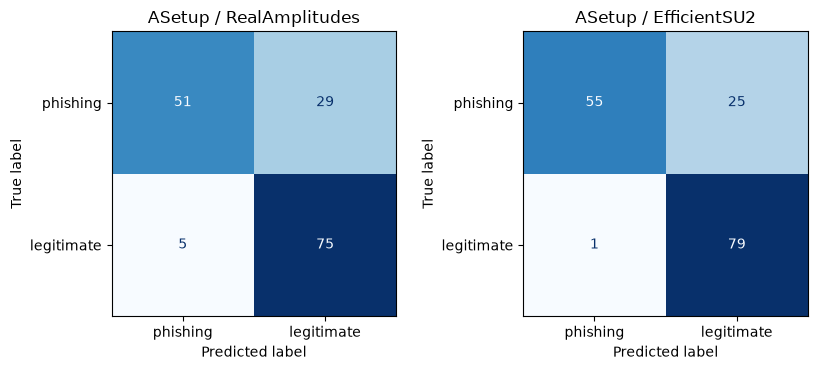

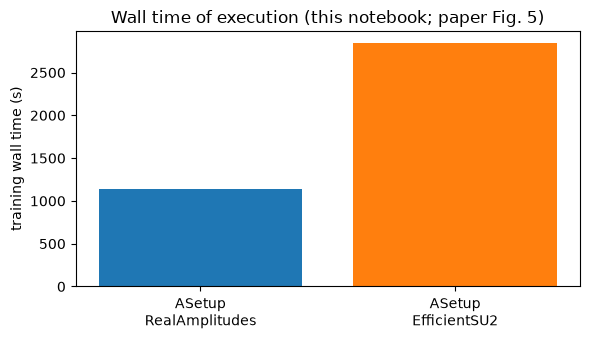

In [11]:
for key, r in results.items():
    print(f"=== {key[0]} / {key[1]} (reps={r['reps']}, {r['n_train']} train / {r['n_test']} test) ===")
    print(classification_report(data[key[0]]["y_test"], r["y_pred"], labels=[0, 1],
                                target_names=["phishing (0)", "legitimate (1)"], digits=3))

table3 = pd.DataFrame([{ "Setup": r["setup"], "Ansatz": r["ansatz"], "reps": r["reps"],
                         "Phishing precision": round(r["phish_precision"], 3),
                         "Phishing recall": round(r["phish_recall"], 3),
                         "Macro F1": round(r["macro_f1"], 3),
                         "Train accuracy": round(r["train_accuracy"], 3),
                         "Wall time fit (s)": round(r["fit_seconds"], 1)} for r in results.values()])
print("This notebook's version of Table III:")
display(table3)

n = len(results)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.8))
for ax, (key, r) in zip(np.atleast_1d(axes), results.items()):
    cm = confusion_matrix(data[key[0]]["y_test"], r["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["phishing", "legitimate"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{key[0]} / {key[1]}")
plt.tight_layout(); plt.show()

# Paper's Fig. 5: wall time per setup and ansatz
fig, ax = plt.subplots(figsize=(6, 3.5))
labels = [f"{k[0]}\n{k[1]}" for k in results]
ax.bar(labels, [r["fit_seconds"] for r in results.values()], color=["tab:blue", "tab:orange"] * (n // 2 + 1))
ax.set_ylabel("training wall time (s)"); ax.set_title("Wall time of execution (this notebook; paper Fig. 5)")
plt.tight_layout(); plt.show()

## 9. Paper versus this notebook

Each row is one number the paper reports. The verdict is **reproduced** when our value lies within 0.05 of the paper's,
**not reached** when it is more than 0.05 below, **exceeded** when more than 0.05 above (0.05 is roughly the sampling
noise of a 160-URL test set, see the next section). Rows for a setup that was not run say so. Wall times are on different
hardware and are compared only as ratios.

In [12]:
PAPER = {  # Table III and Fig. 5 of the paper (precision "0.097" is read as the 0.97 stated in the text)
    ("ASetup", "RealAmplitudes"): dict(phish_precision=0.97, phish_recall=0.81, macro_f1=0.89, wall_s=1534.0),
    ("ASetup", "EfficientSU2"):   dict(phish_precision=0.93, phish_recall=0.87, macro_f1=0.89, wall_s=1534.0 * 1.4),
    ("BSetup", "RealAmplitudes"): dict(phish_precision=0.96, phish_recall=0.80, macro_f1=0.88, wall_s=6584.0 / 2),
    ("BSetup", "EfficientSU2"):   dict(phish_precision=0.90, phish_recall=0.84, macro_f1=0.87, wall_s=6584.0),
}
TOL = 0.05

def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "not run here"
    if abs(ours - paper) <= tol:
        return "reproduced"
    return "exceeded" if ours > paper else "not reached"

# In FAST_MODE the single small run is compared against the paper's ASetup (smaller budget, so expect a gap).
run_for = {"ASetup": "ASetup" if "ASetup" in SETUPS else ("FAST" if "FAST" in SETUPS else None),
           "BSetup": "BSetup" if "BSetup" in SETUPS else None}

rows = []
for (setup, ansatz), p in PAPER.items():
    r = results.get((run_for[setup], ansatz)) if run_for[setup] else None
    note = "" if (r and r["setup"] == setup) else (f"compared with the {r['setup']} run ({r['n_train']}/{r['n_test']} URLs, "
                                                   f"{MAXITER} iterations, reps {r['reps']})" if r else "set RUN_BSETUP = True")
    for metric, label in [("phish_precision", "phishing precision"), ("phish_recall", "phishing recall"), ("macro_f1", "macro F1")]:
        ours = r[metric] if r else None
        rows.append(dict(setup=setup, ansatz=ansatz, claim=label, paper=p[metric],
                         notebook=None if ours is None else round(ours, 3), verdict=verdict(p[metric], ours), note=note))
comparison = pd.DataFrame(rows)
display(comparison)

# wall-time comparison (paper: ASetup RealAmplitudes 1534 s, EfficientSU2 "about 40 % slower"; BSetup EfficientSU2 6584 s)
wt_rows = []
for (setup, ansatz), p in PAPER.items():
    r = results.get((run_for[setup], ansatz)) if run_for[setup] else None
    wt_rows.append(dict(setup=setup, ansatz=ansatz, paper_wall_s=round(p["wall_s"]),
                        notebook_fit_s=None if r is None else round(r["fit_seconds"]),
                        notebook_evaluations=None if r is None else r["evaluations"],
                        verdict="cannot be checked (different hardware)" if r else "not run here"))
wall = pd.DataFrame(wt_rows)
display(wall)
for setup in SETUPS:
    ra, su = results.get((setup, "RealAmplitudes")), results.get((setup, "EfficientSU2"))
    if ra and su:
        ratio = su["fit_seconds"] / ra["fit_seconds"]
        print(f"{setup}: EfficientSU2 / RealAmplitudes wall-time ratio = {ratio:.2f} "
              f"(paper: about 1.4 in ASetup, about 2 in BSetup) -> "
              + ("reproduced (EfficientSU2 is the slower ansatz)" if ratio > 1.0 else
                 "not reproduced here (EfficientSU2 was not slower; wall times on a shared CPU are noisy)"))

# the abstract's headline claims
best_f1 = max(r["macro_f1"] for r in results.values())
best_cls = baseline_first["macro_f1"].max()
print(f"\nPaper: 'maximum macro average F1-score of 0.89'          -> this notebook: {best_f1:.3f} "
      f"({verdict(0.89, best_f1)})")
print(f"Paper: '22 % improvement over [10] (0.67)'               -> cannot be checked: [10] used an Ethereum transaction "
      f"dataset, not PhiUSIIL")
print(f"Best classical baseline on identical inputs (draw 0):    -> macro F1 {best_cls:.3f} "
      f"({'above' if best_cls > best_f1 else 'below'} the best VQC here; the paper reports no classical baseline)")

,setup,ansatz,claim,paper,notebook,verdict,note
0,ASetup,RealAmplitudes,phishing precision,0.97,0.911,not reached,
1,ASetup,RealAmplitudes,phishing recall,0.81,0.637,not reached,
2,ASetup,RealAmplitudes,macro F1,0.89,0.783,not reached,
3,ASetup,EfficientSU2,phishing precision,0.93,0.982,exceeded,
4,ASetup,EfficientSU2,phishing recall,0.87,0.688,not reached,
5,ASetup,EfficientSU2,macro F1,0.89,0.834,not reached,
6,BSetup,RealAmplitudes,phishing precision,0.96,NaN,not run here,set RUN_BSETUP = True
7,BSetup,RealAmplitudes,phishing recall,0.80,NaN,not run here,set RUN_BSETUP = True
8,BSetup,RealAmplitudes,macro F1,0.88,NaN,not run here,set RUN_BSETUP = True
9,BSetup,EfficientSU2,phishing precision,0.90,NaN,not run here,set RUN_BSETUP = True


,setup,ansatz,paper_wall_s,notebook_fit_s,notebook_evaluations,verdict
0,ASetup,RealAmplitudes,1534,1141.0,169.0,cannot be checked (different hardware)
1,ASetup,EfficientSU2,2148,2840.0,300.0,cannot be checked (different hardware)
2,BSetup,RealAmplitudes,3292,NaN,NaN,not run here
3,BSetup,EfficientSU2,6584,NaN,NaN,not run here


ASetup: EfficientSU2 / RealAmplitudes wall-time ratio = 2.49 (paper: about 1.4 in ASetup, about 2 in BSetup) -> reproduced (EfficientSU2 is the slower ansatz)

Paper: 'maximum macro average F1-score of 0.89'          -> this notebook: 0.834 (not reached)
Paper: '22 % improvement over [10] (0.67)'               -> cannot be checked: [10] used an Ethereum transaction dataset, not PhiUSIIL
Best classical baseline on identical inputs (draw 0):    -> macro F1 0.994 (above the best VQC here; the paper reports no classical baseline)


## Reading the paper critically

**Amplitude encoding discards the scale of every URL.** `raw_feature_vector` writes $x/\|x\|$ into the state, so a URL with
one social-network link and one copyright notice becomes the *same* quantum state as a URL with, say, ten of each after
min-max scaling. Section 5 measures what that costs: the last table there trains the same classifiers on the same 29
features *without* the L2 step, so the price of the encoding can be read off directly (exercise 2 goes further). The paper presents the encoding as a neutral requirement of quantum processing; it is in fact a modelling decision that
throws information away before the first gate is applied.

**A test set of 160 URLs cannot resolve differences of 0.01.** With $n = 160$ the standard error of an accuracy near 0.85 is
$\sqrt{0.85 \cdot 0.15 / 160} \approx 0.03$, so a 95 % interval is about $\pm 0.05$; the per-class precision and recall rest
on 80 URLs each and are noisier still. The paper's conclusions that "RealAmplitudes is more consistent in precision" or that
BSetup brings "minor improvements" are all within that noise band, which is why our verdict uses a 0.05 tolerance and why the
classical baselines are repeated over five draws.

**The "22 % improvement" compares two different problems.** The reference model [10] (Ray et al., 2023) classifies Ethereum
*accounts* from transaction-graph statistics, not URLs; it is harder, more imbalanced and has only seven features. A macro F1
of 0.89 on PhiUSIIL is not evidence of a better method than one that scores 0.67 on Etherscan data. The only fair comparison
is against another model on PhiUSIIL, and the paper does not run one.

**A classical model on the same inputs is the missing baseline.** PhiUSIIL is an easy dataset: its authors report classical accuracies
above 99 %, and the feature with the highest label correlation (`URLSimilarityIndex`, |r| = 0.86 on the training pool) alone
separates most of the file. In this notebook logistic regression, an RBF-SVM and a random forest trained on the very
same 32-dimensional unit vectors and the same 640 URLs reach macro F1 values of 0.93-0.99 in under a second (Section 5),
above the paper's best 0.89 and well above the 0.78-0.83 the VQC reaches here after 20-47 minutes of simulation. Whether
PhishVQC "optimises" phishing detection therefore depends entirely on what it is compared with, and the paper chose not to
compare it with anything that uses its inputs.

**Smaller points.** Table III prints a precision of "0.097" for RealAmplitudes where the text says 0.97 (a typo we corrected).
The feature-selection rule is under-specified: "threshold 0.5" with a drop-the-later-column rule gives 29 features on this
data, not 32, and the choice of which column of a correlated pair survives changes the selected set. The sampling of the 640
/ 160 URLs, the split seed and the normaliser are not given, so an exact numerical replication is impossible; our verdicts
are about the *size* of the numbers, not their third decimal. Finally, the loss curves in Section 7 show that the budget is
not what limits the model: both runs plateau at a cross-entropy of about 0.74-0.77 long before the 300th evaluation
(`RealAmplitudes` stops itself at 169), and the training accuracy stays near 0.8. A 5-qubit amplitude-encoded state read out
by parity, with 20 or 40 parameters, simply cannot carve the decision boundary that a random forest finds in the same 29
features; more iterations would not change that, but a different encoding or read-out might (exercise 3).

## Exercises

1. **Noise band.** Re-run Section 7 with `SEED` set to 1, 2 and 3 (keep everything else) and report mean and standard
   deviation of the macro F1 for both ansaetze. Is the paper's difference between RealAmplitudes and EfficientSU2 (0.00 in
   ASetup, 0.01 in BSetup) larger than your standard deviation?
2. **What normalisation costs.** Train the three classical baselines on `scaler.transform(X_num.loc[idx, selected])`
   (min-max only, no zero-padding, no L2 step) for the ASetup draw, and compare with Section 5. Then try `StandardScaler`
   before the L2 step for the VQC. Which change matters more, the scaler or the unit norm?
3. **Angle encoding instead of amplitude encoding.** Replace `raw_feature_vector` by `zz_feature_map(5, reps=1)` applied
   to the five features with the highest label correlation (scaled to $[0, \pi]$). Does the Aer sampler now work? Compare
   macro F1 and wall time with PhishVQC.
4. **Correlation rule.** Implement the alternative reading of the paper's rule, "keep every feature whose absolute
   correlation with the label is at least 0.5", and the Spearman version of the pairwise filter. How many features survive
   each rule, and does the VQC's macro F1 change by more than the noise band of exercise 1?
5. **Budget versus data.** The paper argues that circuit repetitions matter more than dataset size. Run ASetup with
   `reps = 4` and BSetup with `reps = 3` (set `RUN_BSETUP = True`, or scale both down in `FAST_MODE`) and build a 2 x 2 table
   of macro F1. Does the data support the paper's conclusion once the noise band is taken into account?